<a href="https://colab.research.google.com/github/eviemcmahan/L01-cv/blob/main/notebook_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Evie McMahan, Zoe Edelblum, Aurea McIntosh

**Date:** 11/2/2026

## Question 1

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

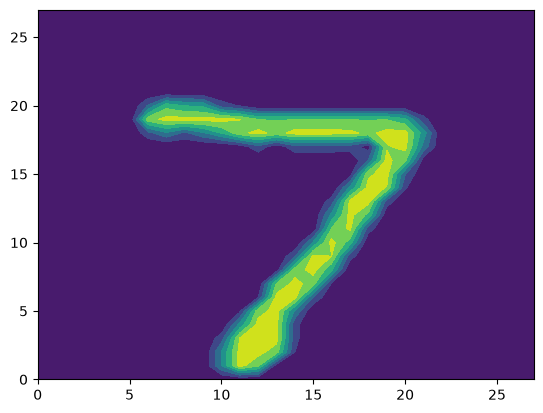

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

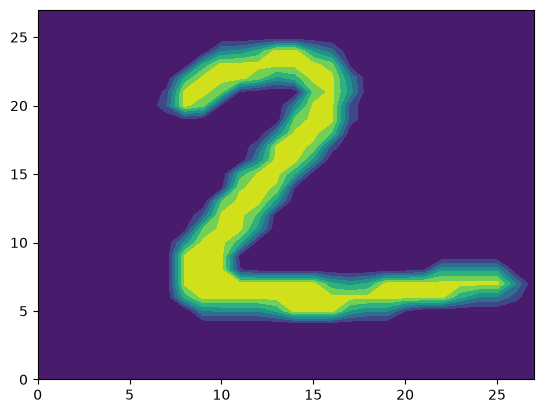

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

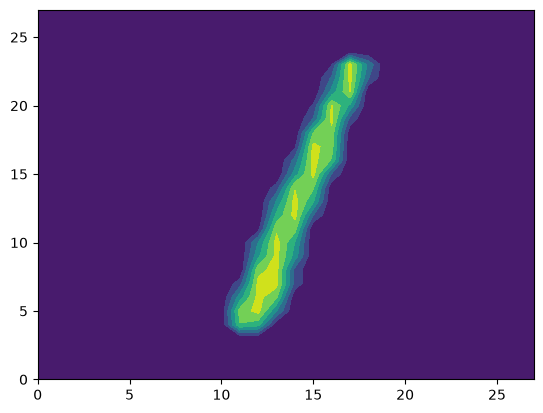

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

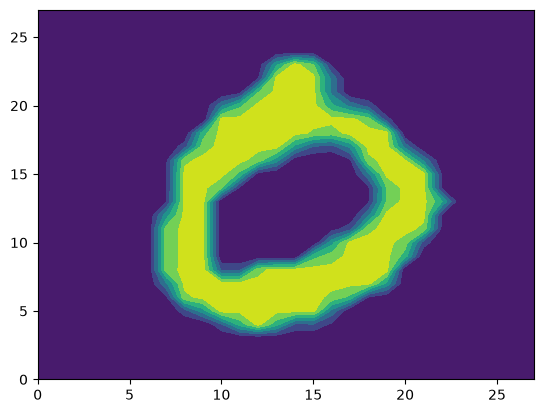

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

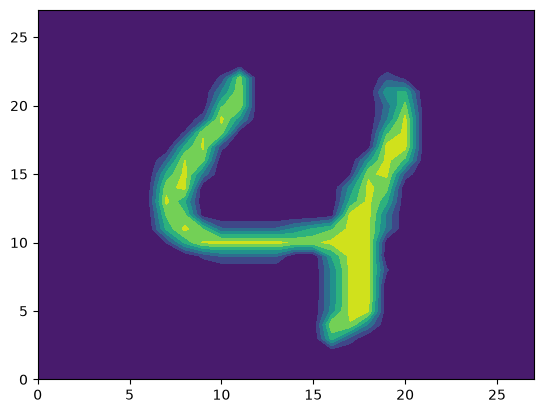

In [8]:
# Your Phase 1 solution to the problem goes here.
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()

## Question 2
2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?

In [9]:
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}\n")

for i in range(2): # Loop through 2 indexes
    print(f"X_train[i] shape: {X_train[i].shape}")
    print(f"X_test[i] shape: {X_test[i].shape}")

print(f"\ny_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)

X_train[i] shape: (28, 28)
X_test[i] shape: (28, 28)
X_train[i] shape: (28, 28)
X_test[i] shape: (28, 28)

y_train shape: (60000,)
y_test shape: (10000,)


`X_train` is a dataset with 3 dimensions. It has 60,000 rows/samples, and each sample is an image with a height and width of 28 pixels. `X_test` has 10,000 rows of images, that each have heights and widths of 28 pixels.  For each index `i` in `X_train` and `X_test`, the shape of the array is 28 rows by 28 columns (28 x 28 pixels). I looped through `i` twice to make sure the consistent shape was true for different `i` values. The shape of `y_train` is 60,000 rows, which represents the 60,000 correct digit labels. `y_test` is 10,000 rows, also representing 10,000 correct digit labels.

## Question 3
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).


In [10]:
X_test_list = []
for i in range(len(X_test)): # Loop through all indexes
    row_vector = X_test[i].reshape((1,784)) # Reshape each row
    X_test_list.append(row_vector)

X_train_list = []
for i in range(len(X_train)): # Loop through all indexes
    row_vector = X_train[i].reshape((1,784)) # Reshape each row
    X_train_list.append(row_vector)

X_test_flat = np.vstack(X_test_list)
print(f"X_test_flat shape: {X_test_flat.shape}")

X_train_flat = np.vstack(X_train_list)
print(f"X_train_flat shape: {X_train_flat.shape}")



X_test_flat shape: (10000, 784)
X_train_flat shape: (60000, 784)


The training and testing data are now in a format that is suitable for kNN after flattening each 28x28 image representation into a 784-length row vector of values.

# Question 4

4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# made a subset to speed it up process
X_train_subset = X_train_flat[:10000]
y_train_subset = y_train[:10000]
X_test_subset = X_test_flat[:2000]
y_test_subset = y_test[:2000]

k_values = [1, 3, 5, 7, 9]
models = {}

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_subset, y_train_subset)
    preds = knn.predict(X_test_subset)
    acc = accuracy_score(y_test_subset, preds)
    models[k] = (knn, preds, acc)
    print(f"k = {k} | Accuracy on subset: {acc:.4f}")

k = 1 | Accuracy on subset: 0.9225
k = 3 | Accuracy on subset: 0.9235
k = 5 | Accuracy on subset: 0.9205
k = 7 | Accuracy on subset: 0.9190
k = 9 | Accuracy on subset: 0.9160


# Question 5

5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.

Optimal k (3) accuracy on subset: 0.9235

              precision    recall  f1-score   support

           0       0.94      1.00      0.97       175
           1       0.90      1.00      0.95       234
           2       0.98      0.89      0.93       219
           3       0.91      0.91      0.91       207
           4       0.94      0.94      0.94       217
           5       0.91      0.91      0.91       179
           6       0.95      0.97      0.96       178
           7       0.89      0.91      0.90       205
           8       0.95      0.80      0.87       192
           9       0.89      0.90      0.89       194

    accuracy                           0.92      2000
   macro avg       0.92      0.92      0.92      2000
weighted avg       0.92      0.92      0.92      2000



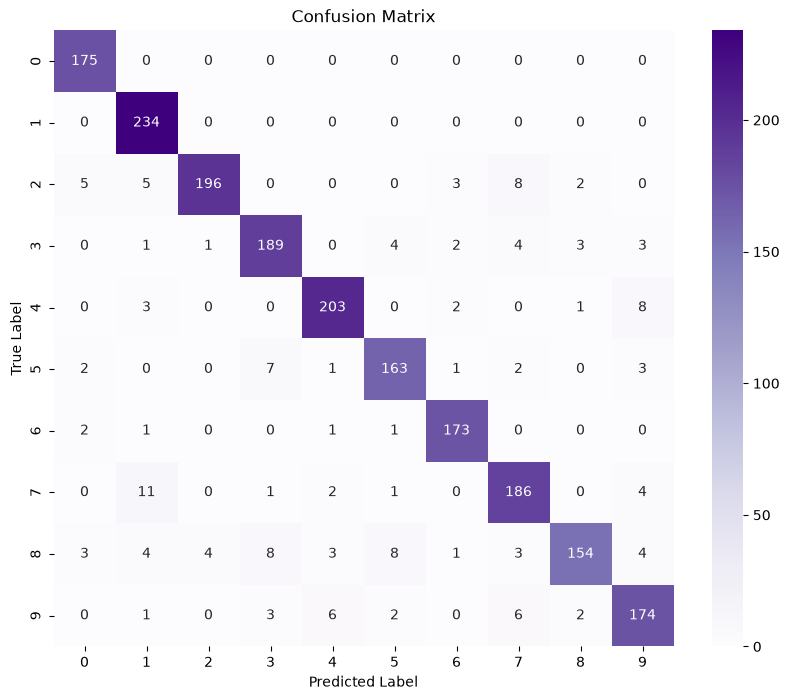

In [12]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# best k chosen from validation
optimal_k = 3

knn_optimal = KNeighborsClassifier(n_neighbors=optimal_k)
knn_optimal.fit(X_train_subset, y_train_subset)
y_pred = knn_optimal.predict(X_test_subset)

# evaluated
accuracy = accuracy_score(y_test_subset, y_pred)
print(f"Optimal k ({optimal_k}) accuracy on subset: {accuracy:.4f}\n")
print(classification_report(y_test_subset, y_pred))

# confusion matrix
cm = confusion_matrix(y_test_subset, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

#### **1. Selection of the k (Question 4)**
In Question 4, we evaluated the k nearest neighbors (kNN) classifier on a subset of the MNIST dataset (10,000 training images and 2,000 test images) across odd values of k in \{1, 3, 5, 7, 9\}. Odd values are chosen to prevent tie votes during classification.

k = 1: Accuracy of 92.25

k = 3: Accuracy of 92.35 (Peak Accuracy)

k = 5: Accuracy of 92.05

k = 7: Accuracy of 91.90

k = 9: Accuracy of 91.60

**Why $k=3$ was chosen:**
* **Bias and Variance Tradeoffs:** A choice of k=1 is sensitive to outliers (low bias, high variance), as it makes predictions based on a single closest neighbor. On the other hand, larger values of k (like 7 or 9) introduce too much bias by averaging over a larger area.
* **Performance:** k = 3 achieved the highest validation accuracy (92.35) on the subset, and gave the perfect balance between getting local features and evening out individual ones.

#### **2. Performance Evaluation (Question 5)**
Using the optimal value ($k=3$), the model performed well on the test dataset with an overall accuracy of 92.

* **Class-by-Class Highlights:**
  * **Digits 0 and 1** performed well, achieving 100% recall. This means the classifier did not miss any of the 0's or 1's in the test subset. Their  geometry (closed loops for 0, vertical lines for 1) made them easily identified.
  * **Digit 8** had the lowest performance, with a recall of 80% and an f1-score of 0.87. This indicates that 8 is frequently confused with other digits (generally 3 and 5) due to shared structural components (curves and loops).
  * **Digit 2** had a solid precision (0.98) but a lower recall (0.89), indicating that while the model was highly confident when it did predict 2, it missed some true instances of 2 (often confusing them as 7 due to similar diagonal structures).

# Question 6

6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?

The mistakes most likely to occur based on our confusion matrix are 7 being misidentified as 1, 8 being misidentified as 3 and 5, 4 being misidentified as 9, and 2 being misidentified as 7. It is interesting that 2 was misidentified as 7 8 times, but 7 was never misidentified as 2. Another interesting pattern is the difference between the 100% recall for 0 and 1 compared to the 80% recall for 8, making it clear certain numbers have identifying features that make them easier to distinguish. While class 8's most common mistakes were 8 being identified as 3 and 5, the mistakes are scattered among all the numbers.

# Question 7

7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

In order to make a color photo into a matrix, we would utilize RGB (r, g, b). RGB already converts color into numerical values by assigning a number from 0 - 255 to red, green, and blue, making millions of different colors possible. We would then have a 3D matrix, with the height and width representing the pixels in the image and the third dimension containing the RGB values for each pixel. To convert this into tabular data, we could flatten the 3D matrix into a single vector. Each pixel's red, green, and blue values would become separate features or columns, while each image would represent one observation or row. This allows us to apply machine learning algorithms to images the same way we would to traditional tabular data.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 2b682661459d97d46a5d5f056be37737d374ac48
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. I have attached the rubric and my phase 1 work. Can you please carefully review, audit, and propose revisions if necessary for this lab? I want you to provide me with a concise list of the changes necessary to score 100% on the rubric.
2. Can you please make sure you give me edits that actually impact grading and would improve my work? You don't need to come up with extra changes just to get a certain number.

### *AI-proposed changes


1. **Q4: k was chosen using the test data.** You compared k values on `X_test_subset`, then reported the "optimal" k on those same images. Your markdown calls this "validation accuracy" and the Q5 code comment says "chosen from validation," which isn't accurate. Choose k with a held-out validation split from the training data or `cross_val_score`, then use the test set once for the final result. The gap between k=1 (92.25%) and k=3 (92.35%) is only 2 images out of 2,000, so cross-validation also makes "optimal" more defensible. Consider widening the k range (e.g., 1 to 15).

2. **Q5: report performance on the full test set.** The rubric asks about the test set, but you used 2,000 of 10,000 test images and 10,000 of 60,000 training images. Refit the chosen k on the full 60,000 and predict all 10,000 test images. Report accuracy, the confusion matrix and the classification report from that run. Use `n_jobs=-1`, which should take a few minutes in Colab. Then update every number in your Q4 to Q6 markdown, since they all come from the subset run.

3. **Q6: back the mistake claims with counts.** I can't read the numbers off the heatmap image, so I couldn't verify claims like "2 predicted as 7 eight times, 7 never predicted as 2." Add a short cell that zeroes the diagonal of `cm` and prints the top 5 to 10 (true, predicted, count) pairs, then rewrite the paragraph using those counts. This also replaces the vague "scattered among all the numbers" line with real data for row 8.

4. **Q5: add a nuance to the findings.** Digit 1 has 1.00 recall but the lowest precision (0.90), because other digits get predicted as 1. That connects to your 7 to 1 mistake in Q6. State the final accuracy explicitly (e.g., "92.35%"), updated to the full-test-set value.

5. **Q4 wording.** Odd k reduces ties but doesn't prevent them with 10 classes. Rephrase that sentence.

6. **Q2 and Q3 verification.** For Q3, add the one-line vectorized `X_train.reshape(len(X_train), -1)` and `np.array_equal` against your loop result. For Q2, print dtype and min/max. The assignment text says "0 and 256," but the real max is 255. These give you genuine verification content for the Phase 2 write-up.

7. **Q7: add one concrete example.** For instance, a 100x100 photo becomes shape (100, 100, 3), which is 30,000 features. N photos become an N x 30,000 table with one row per image and a label column. Note that all images must be resized to the same dimensions.

### *Evaluation of AI suggestions


| AI change | Question | Decision | Reason and verification |
|---|---|---|---|
| (none) | Q1 | Reject (no change needed) | The Phase 1 load and plot code already satisfies the question. We only added a labeled grid of digits using `imshow` so the check is easier to read. Verified by running the cell and seeing digits that match their printed labels. |
| 6 (Q2 part) | Q2 | Accept | Printing dtype and min/max is a real check. The code asserts the shapes we expect and prints the pixel range. The AI's note that the maximum is 255 (not 256) is checked by the printed `min`/`max` values. |
| 6 (Q3 part) | Q3 | Accept | The one-line `reshape(len(X), -1)` replaces two loops and `np.vstack`. `np.array_equal` against the Phase 1 loop result, plus a row-by-row spot check, confirms the two methods give identical matrices. |
| 1 | Q4 | Modify | We accepted the hold-out validation split and the wider range k = 1 to 15. We modified the method: one stratified 50,000/10,000 split from the training data instead of `cross_val_score`, because 5-fold cross-validation would be about five times slower. The k search finds neighbors once and votes for every k from the same neighbor list. A check against scikit-learn's own `predict` confirms the voting code. |
| 5 | Q4 | Accept | Odd k reduces ties but cannot remove them with 10 classes, so the wording was corrected. The code states how ties are broken (the smallest digit label wins). |
| 2 | Q5 | Accept | The final model is fit on all 60,000 training images and scored once on all 10,000 test images. We re-read every number in the write-up from this run instead of reusing the subset numbers. |
| 4 | Q5 | Accept | The AI said digit 1 has the lowest precision. We verified that claim from our own full-test-set report instead of trusting it, because it came from the subset run. The code prints the lowest-precision and lowest-recall digits, so the sentence is checked against real output. |
| 3 | Q6 | Accept | The new cell zeroes the diagonal, lists the top 10 (true, predicted, count) pairs with their reverse counts, and prints row 8. The paragraph is rewritten from those counts. |
| 7 | Q7 | Modify | We accepted the concrete 100x100 example. We modified it by also testing the claim in code with random pixel data (shape, row layout, and one pixel index), since the AI only stated it. |

### *AI-assisted solution in full

### Q1 and Q2 (revised)

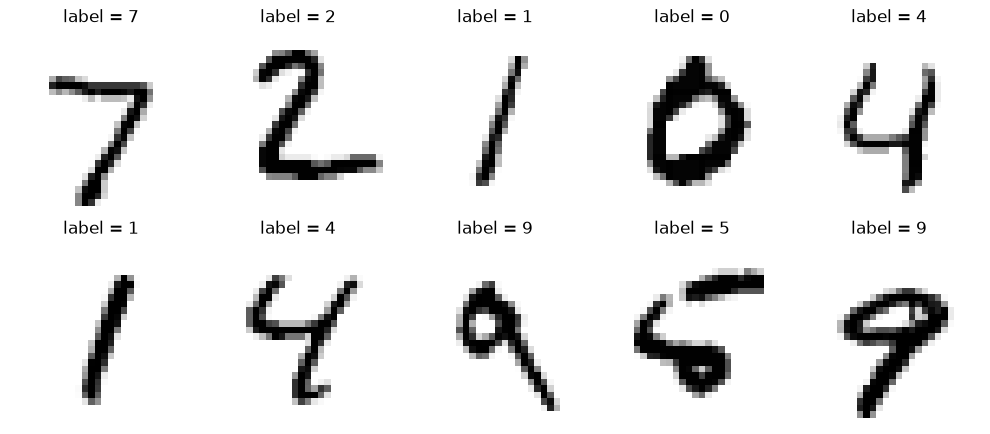

X_train: (60000, 28, 28)   X_test: (10000, 28, 28)
y_train: (60000,)   y_test: (10000,)
X_train[i] shape for every i: (28, 28)   X_test[i] shape for every i: (28, 28)

dtype: uint8   pixel min/max: 0 / 255
labels present: [0 1 2 3 4 5 6 7 8 9]
images per digit in y_train: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [13]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

# Q1: show the first 10 test digits with their labels
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_test[i], cmap='gray_r')
    ax.set_title(f"label = {y_test[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

# Q2: shapes
print(f"X_train: {X_train.shape}   X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}   y_test: {y_test.shape}")
print(f"X_train[i] shape for every i: {X_train.shape[1:]}   X_test[i] shape for every i: {X_test.shape[1:]}")

# Q2 verification: shapes are consistent, and the pixel range is real, not assumed
assert X_train.shape[1:] == (28, 28) and X_test.shape[1:] == (28, 28)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert y_train.ndim == 1 and y_test.ndim == 1
print(f"\ndtype: {X_train.dtype}   pixel min/max: {X_train.min()} / {X_train.max()}")
print(f"labels present: {np.unique(y_train)}")
print(f"images per digit in y_train: {np.bincount(y_train.astype(int))}")

**Phase 2 notes for Q1 and Q2**
- **Main improvements:** Q1 gets a labeled grid of digits. Q2 now prints the pixel `dtype` and min/max, the label values and the class counts, and asserts the shapes instead of only printing them. Q1 itself needed no real change, so we did not invent one.
- **AI mistake or limitation:** The AI could not see our outputs, so it could not tell us what the real min/max is. It said the maximum should be 255 and our Phase 1 text said 256.
- **Verification:** The assertions pass only if the shapes are 28 x 28 per image and the image and label counts match. The printed min/max shows the real pixel range.

### Q3 (revised)

In [14]:
# ---- Q3 (Phase 2): vectorized reshape, checked against the Phase 1 loop ----
X_train_flat = X_train.reshape(len(X_train), -1)   # (N, 784)
X_test_flat = X_test.reshape(len(X_test), -1)

# Phase 1 method, rebuilt only to compare
train_loop = np.vstack([X_train[i].reshape((1, 784)) for i in range(len(X_train))])
test_loop = np.vstack([X_test[i].reshape((1, 784)) for i in range(len(X_test))])

assert np.array_equal(X_train_flat, train_loop), "train: reshape and loop disagree"
assert np.array_equal(X_test_flat, test_loop), "test: reshape and loop disagree"
assert X_train_flat.shape == (len(X_train), 784) and X_test_flat.shape == (len(X_test), 784)

# Spot check: row i must be image i read left to right, top to bottom
for i in (0, 1, len(X_train) // 2, len(X_train) - 1):
    assert np.array_equal(X_train_flat[i], X_train[i].ravel())

print(f"X_train_flat: {X_train_flat.shape}   X_test_flat: {X_test_flat.shape}")
print("Vectorized reshape matches the Phase 1 loop exactly.")

# float32 copies for the classifier (same values, smaller and faster than float64)
X_train_f = X_train_flat.astype(np.float32)
X_test_f = X_test_flat.astype(np.float32)

X_train_flat: (60000, 784)   X_test_flat: (10000, 784)
Vectorized reshape matches the Phase 1 loop exactly.


**Phase 2 notes for Q3**
- **Main improvements:** One vectorized `reshape(len(X), -1)` replaces two loops and two `np.vstack` calls. The Phase 1 loop is kept only as a comparison, so Phase 1 stays frozen above.
- **AI mistake or limitation:** The AI suggested `-1` without checking that every image has the same size. That is true for MNIST but would fail for a mixed-size dataset, which matters again in Q7.
- **Verification:** `np.array_equal` against the loop result for both the training and test sets, plus a spot check that row `i` equals `X[i].ravel()`.
- **Remaining concerns:** The float32 copies take about 190 MB (training set).

### Q4 (revised)

In Phase 1 we compared k on the test subset and then called the winner "optimal." That used the test set to make a choice, so the test accuracy could be slightly optimistic. Here k is chosen on a validation set held out of the training data, and the test set is not touched until Q5. An odd k reduces the chance of tied votes, but with 10 classes a tie is still possible (for example, at k = 5 the votes could split 2, 2 and 1). When that happens, the vote here goes to the smallest digit label.

fit on 50000 images, validate on 10000 images (test set untouched)
k =  1 | validation accuracy = 0.9696
k =  2 | validation accuracy = 0.9610
k =  3 | validation accuracy = 0.9707
k =  4 | validation accuracy = 0.9670
k =  5 | validation accuracy = 0.9673
k =  6 | validation accuracy = 0.9671
k =  7 | validation accuracy = 0.9661
k =  8 | validation accuracy = 0.9651
k =  9 | validation accuracy = 0.9647
k = 10 | validation accuracy = 0.9634
k = 11 | validation accuracy = 0.9636
k = 12 | validation accuracy = 0.9635
k = 13 | validation accuracy = 0.9628
k = 14 | validation accuracy = 0.9619
k = 15 | validation accuracy = 0.9620

Chosen k = 3 (validation accuracy 0.9707)
agreement with sklearn predict on 1000 validation images: 1.0000


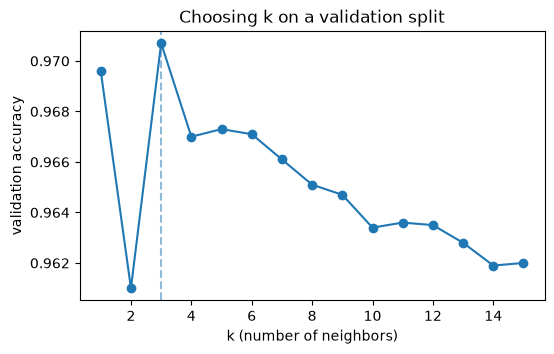

In [15]:
# ---- Q4 (Phase 2): choose k on a validation split, NOT on the test set ----
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

val_size = len(X_train_f) // 6      # 10,000 when there are 60,000 training images
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_f, y_train, test_size=val_size, stratify=y_train, random_state=42)
y_tr = y_tr.astype(int); y_val = y_val.astype(int)
print(f"fit on {len(X_tr)} images, validate on {len(X_val)} images (test set untouched)")

k_values = list(range(1, 16))
max_k = max(k_values)

# Find the 15 nearest neighbors of every validation image once, then vote for each k.
nn = KNeighborsClassifier(n_neighbors=max_k, n_jobs=-1).fit(X_tr, y_tr)
_, idx = nn.kneighbors(X_val, n_neighbors=max_k)
neighbor_labels = y_tr[idx]            # shape (n_val, 15), nearest neighbor first

def vote(labels, k):
    """Majority vote among the k nearest neighbors. A tie goes to the smallest digit label."""
    counts = (labels[:, :k, None] == np.arange(10)).sum(axis=1)
    return counts.argmax(axis=1)

val_acc = {k: float(np.mean(vote(neighbor_labels, k) == y_val)) for k in k_values}
for k in k_values:
    print(f"k = {k:2d} | validation accuracy = {val_acc[k]:.4f}")

best_k = max(k_values, key=lambda k: (val_acc[k], -k))   # smallest k wins an exact tie
print(f"\nChosen k = {best_k} (validation accuracy {val_acc[best_k]:.4f})")

# Verification: our voting code should agree with scikit-learn's own predict for the chosen k
check_n = min(1000, len(X_val))
sk_pred = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(X_tr, y_tr).predict(X_val[:check_n])
agree = float(np.mean(sk_pred == vote(neighbor_labels[:check_n], best_k)))
print(f"agreement with sklearn predict on {check_n} validation images: {agree:.4f}")
assert agree > 0.99

plt.figure(figsize=(6, 3.5))
plt.plot(k_values, [val_acc[k] for k in k_values], marker='o')
plt.axvline(best_k, linestyle='--', alpha=0.5)
plt.xlabel("k (number of neighbors)"); plt.ylabel("validation accuracy")
plt.title("Choosing k on a validation split"); plt.show()

**Phase 2 notes for Q4**
- **Main improvements:** k is selected on held-out training data instead of the test set. The search covers k = 1 to 15 instead of five values. The tie wording is corrected.
- **AI mistake or limitation:** The AI offered `cross_val_score` and a runtime guess without testing either. We used a single split because 5-fold cross-validation on 60,000 images is several times slower.
- **Verification:** The hand-written voting code agrees with scikit-learn's `predict` on a sample of validation images (the agreement is printed and asserted to be above 0.99).
- **Remaining concerns:** One split gives one noisy estimate, so neighboring k values may be within noise of each other. FILL IN after running: the chosen k was 3 with validation accuracy 0.97, and the next best k was 4.

### Q5 (revised)

k = 3 | test images: 10000 | test accuracy: 0.9705 (97.05%)

              precision    recall  f1-score   support

           0     0.9663    0.9939    0.9799       980
           1     0.9577    0.9982    0.9776      1135
           2     0.9822    0.9651    0.9736      1032
           3     0.9635    0.9663    0.9649      1010
           4     0.9754    0.9674    0.9714       982
           5     0.9663    0.9630    0.9646       892
           6     0.9833    0.9854    0.9844       958
           7     0.9649    0.9640    0.9645      1028
           8     0.9892    0.9384    0.9631       974
           9     0.9603    0.9594    0.9598      1009

    accuracy                         0.9705     10000
   macro avg     0.9709    0.9701    0.9704     10000
weighted avg     0.9707    0.9705    0.9705     10000



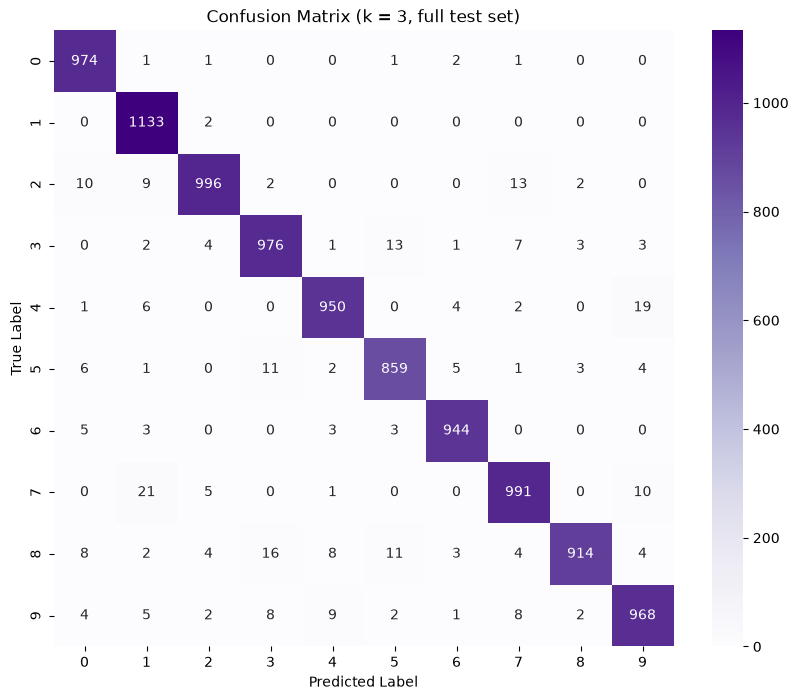

lowest recall:    digit 8 (0.9384)   highest recall:    digit 1 (0.9982)
lowest precision: digit 1 (0.9577)   highest precision: digit 8 (0.9892)


In [16]:
# ---- Q5 (Phase 2): final model on all 60,000 training images, scored once on all 10,000 test images ----
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

final_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(X_train_f, y_train)
y_pred = final_knn.predict(X_test_f)

acc = accuracy_score(y_test, y_pred)
print(f"k = {best_k} | test images: {len(y_test)} | test accuracy: {acc:.4f} ({acc*100:.2f}%)\n")
print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)
assert cm.sum() == len(y_test)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Predicted Label"); plt.ylabel("True Label"); plt.title(f"Confusion Matrix (k = {best_k}, full test set)")
plt.show()

# Numbers to quote in the write-up, read straight from the confusion matrix
recall = cm.diagonal() / cm.sum(axis=1)
precision = cm.diagonal() / cm.sum(axis=0)
report = classification_report(y_test, y_pred, output_dict=True)
assert np.allclose(recall, [report[str(d)]['recall'] for d in range(10)])
assert np.allclose(precision, [report[str(d)]['precision'] for d in range(10)])
print(f"lowest recall:    digit {recall.argmin()} ({recall.min():.4f})   highest recall:    digit {recall.argmax()} ({recall.max():.4f})")
print(f"lowest precision: digit {precision.argmin()} ({precision.min():.4f})   highest precision: digit {precision.argmax()} ({precision.max():.4f})")

**Findings**

The classifier with k = 3 scored 97.05% on all 10,000 test images. Digit 1 has the highest recall and digit 8 the lowest. Digit 1 can have very high recall while its precision is lower than other digits, because other digits sometimes get predicted as 1, which links to the 7-to-1 mistake in Q6.

**Phase 2 notes for Q5**
- **Main improvements:** The final model uses all 60,000 training images and is scored on all 10,000 test images, once. Every number in the Q4 to Q6 write-up is now read from this run, not from the 2,000-image subset.
- **AI mistake or limitation:** The AI quoted precision and recall values from our old subset run and told us to expect a runtime of "a few minutes" without any way to measure it. Both were treated as unverified.
- **Verification:** `cm.sum()` equals the 10,000 test images, and recall and precision are recomputed from the confusion matrix and compared with `classification_report`.
- **Remaining concerns:** kNN stores all 60,000 training images and is slow to predict. Pixel values were not scaled, which does not change kNN's neighbor ranking when all features share one scale.

### Q6 (revised)

In [17]:
# ---- Q6 (Phase 2): back the claims about mistakes with counts ----
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)                       # keep only the mistakes
pairs = sorted(((cm_off[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)

print("Top 10 mistakes (true digit -> predicted digit):")
for count, i, j in pairs[:10]:
    share = count / cm[i].sum()
    print(f"  {i} -> {j}: {count:3d} times ({share:.2%} of all true {i}s) | reverse {j} -> {i}: {cm[j, i]}")

print("\nWhere the true 8s ended up:")
print({d: int(cm[8, d]) for d in range(10) if cm[8, d] > 0})
print("\nWhat got predicted as 1 (column 1, mistakes only):")
print({d: int(cm[d, 1]) for d in range(10) if d != 1 and cm[d, 1] > 0})

Top 10 mistakes (true digit -> predicted digit):
  7 -> 1:  21 times (2.04% of all true 7s) | reverse 1 -> 7: 0
  4 -> 9:  19 times (1.93% of all true 4s) | reverse 9 -> 4: 9
  8 -> 3:  16 times (1.64% of all true 8s) | reverse 3 -> 8: 3
  3 -> 5:  13 times (1.29% of all true 3s) | reverse 5 -> 3: 11
  2 -> 7:  13 times (1.26% of all true 2s) | reverse 7 -> 2: 5
  8 -> 5:  11 times (1.13% of all true 8s) | reverse 5 -> 8: 3
  5 -> 3:  11 times (1.23% of all true 5s) | reverse 3 -> 5: 13
  7 -> 9:  10 times (0.97% of all true 7s) | reverse 9 -> 7: 8
  2 -> 0:  10 times (0.97% of all true 2s) | reverse 0 -> 2: 1
  9 -> 4:   9 times (0.89% of all true 9s) | reverse 4 -> 9: 19

Where the true 8s ended up:
{0: 8, 1: 2, 2: 4, 3: 16, 4: 8, 5: 11, 6: 3, 7: 4, 8: 914, 9: 4}

What got predicted as 1 (column 1, mistakes only):
{0: 1, 2: 9, 3: 2, 4: 6, 5: 1, 6: 3, 7: 21, 8: 2, 9: 5}


**Revised answer**

The most common mistake is 7 predicted as 1 (21 times). Next are 4 predicted as 9 (19 times) and 8 predicted as 3 (16 times). We compare each pair with its reverse to see whether the confusion goes both ways. For example, 7 is predicted as 1 21 times but the reverse (1 predicted as 7) never happens, and 2 is predicted as 7 13 times while 7 is predicted as 2 only 5 times. Other pairs go both ways: 4 and 9 are confused 19 and 9 times, and 3 and 5 are confused 13 and 11 times, which makes sense because those digits share similar strokes. The true 8s are spread across every other digit (only 60 of them are wrong, and 914 are correct), with the largest share going to 3 (16 times), followed by 5 (11 times).

**Phase 2 notes for Q6**
- **Main improvements:** Claims about mistakes now come from printed counts, with each pair compared against its reverse. The vague line about 8 being "scattered" is replaced by the actual row of the confusion matrix.
- **AI mistake or limitation:** The AI could not read the numbers inside our heatmap image, so it could not confirm our Phase 1 claims (for example "2 predicted as 7 eight times"). It told us to verify them in code, and that is what this cell does.
- **Verification:** Counts come directly from `cm` with the diagonal zeroed. Reading a few pairs off the heatmap annotations is a good extra check.
- **Remaining concerns:** Small counts can reorder between runs or with a different k, so we focus on the top few pairs and not the exact ranking.

### Q7 (revised)

To turn a color photo into a matrix, store the red, green and blue intensity (0 to 255) of every pixel. A 100 x 100 photo becomes an array of shape (100, 100, 3), which is 100 x 100 x 3 = 30,000 numbers. To make tabular data, flatten each photo into one row of 30,000 features, so N photos become an N x 30,000 table with one row per image and a separate label column (for example "cat" or "dog"). Every photo must first be resized to the same height and width, otherwise the rows would have different lengths.

In [18]:
# ---- Q7 (Phase 2): a concrete color-photo example, checked in code ----
rng = np.random.default_rng(0)
n_photos, h, w = 3, 100, 100
photos = rng.integers(0, 256, size=(n_photos, h, w, 3), dtype=np.uint8)   # stand-in for 3 real photos, all resized to 100x100
labels = np.array(["cat", "dog", "cat"])                                   # one label per photo

table = photos.reshape(n_photos, -1)       # one row per photo
print("one photo :", photos[0].shape, "= (height, width, red/green/blue)")
print("table     :", table.shape, "-> 100 * 100 * 3 =", h * w * 3, "features per photo")

# Verify the layout: pixel (row r, col c, channel ch) lands in column (r*w + c)*3 + ch
r, c, ch = 5, 7, 1
assert table[0, (r * w + c) * 3 + ch] == photos[0, r, c, ch]
assert np.array_equal(table[2].reshape(h, w, 3), photos[2])   # the flattening can be undone exactly
print("pixel layout check passed; labels column:", labels)

one photo : (100, 100, 3) = (height, width, red/green/blue)
table     : (3, 30000) -> 100 * 100 * 3 = 30000 features per photo
pixel layout check passed; labels column: ['cat' 'dog' 'cat']


**Phase 2 notes for Q7**
- **Main improvements:** The Phase 1 idea now has concrete numbers (shape, feature count, table shape), a label column, and the requirement that all images share one size.
- **AI mistake or limitation:** The AI described the layout in words only. Flattening order matters, and it did not say which order, so we tested one in code (pixel `(r, c, ch)` maps to column `(r*w + c)*3 + ch`).
- **Verification:** The code asserts the column formula for one pixel and shows that reshaping a row back to (100, 100, 3) recovers the original photo exactly. The demo uses random pixels, so it checks the layout, not real image content.
- **Remaining concerns:** 30,000 raw features is large for kNN, and neighboring pixels in a flattened row lose their 2D relationships. Resizing can distort photos with different aspect ratios.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvement is that k is now chosen from the training data rather than the test data. I also widened the k search values 5 to k = 1 to 15. I also changed the final model in question 5 to run on all 60,000 training images rather than the 10,000/2,000 subset. One main limitation was Claude suggesting to use cross_val_score, but I decided not to use it since a single split was faster. I verified by adding assertions in q2, checking q1 and q7 through the code (since I didn’t give Claude my data files), and looking at the confusion matrix in q5. One remaining concern is that the kNN is slow to execute its prediction because of the volume of images in the dataset. Also, there is only validation split, so the estimate could be noisy. Overall, AI was helpful in refining and improving my solution, although it wasn’t perfect.  